# USD/RUB: можно ли обойти последнее известное значение?

Первый проект для портфолио аналитика. Проверяем полезность усложнения прогноза: сравниваем baseline, ARIMA и Prophet на одинаковых датах. Источник — [Банк России](https://www.cbr.ru/development/sxml/).

## 1. Вопрос и доступные данные

Цель — прогнозировать следующее наблюдение официального USD/RUB. Это не прогноз следующего календарного дня и не курс обмена в приложении банка. Архив 2018–2025 зафиксирован, скачки не удаляются, выходные не заполняются.

Для пересчёта: `python fx_forecast.py`, затем `python make_notebook.py`. Здесь открываем результаты уже выполненного backtest; исходная реализация находится в `fx_forecast.py`.

In [1]:
from pathlib import Path
import hashlib
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from fx_forecast import parse_cbr_xml, split_positions, metrics

ROOT = Path.cwd()
payload = (ROOT / 'data/raw/usd_rub_2018_2025.xml').read_bytes()
source = json.loads((ROOT / 'data/raw/source.json').read_text(encoding='utf-8'))
assert hashlib.sha256(payload).hexdigest() == source['sha256']
df = parse_cbr_xml(payload)
print(f'{len(df)} наблюдений; {df.date.min().date()} — {df.date.max().date()}')
display(df.head())

D:\projects\pets\fx-forecast\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


1973 наблюдений; 2018-01-10 — 2025-12-31


,date,rate
0,2018-01-10,57.0463
1,2018-01-11,56.8734
2,2018-01-12,56.9957
3,2018-01-13,56.6019
4,2018-01-16,56.3569


In [2]:
quality = pd.Series({
    'Дубликаты дат': int(df.date.duplicated().sum()),
    'Пропуски курса': int(df.rate.isna().sum()),
    'Неположительные курсы': int((df.rate <= 0).sum()),
    'Минимальный курс': df.rate.min(),
    'Максимальный курс': df.rate.max(),
})
display(quality.to_frame('Значение'))

,Значение
Дубликаты дат,0.0000
Пропуски курса,0.0000
Неположительные курсы,0.0000
Минимальный курс,51.1580
Максимальный курс,120.3785


## 2. Временное разделение

Последние 180 наблюдений: 60 для выбора параметров и 120 для финальной оценки. На validation оцениваем каждую пятую точку, на test — каждую. В каждой точке доступны только 750 предшествующих значений. По мере поступления факта модель переобучается; тестовые наблюдения могут становиться историей для следующих прогнозов, но не участвуют в выборе настроек.

In [3]:
validation_start, test_start = split_positions(len(df))
splits = []
for name, part in [('Train', df.iloc[:validation_start]),
                   ('Validation', df.iloc[validation_start:test_start]),
                   ('Test', df.iloc[test_start:])]:
    splits.append({'Период': name, 'Начало': part.date.min().date(),
                   'Конец': part.date.max().date(), 'Наблюдений': len(part)})
display(pd.DataFrame(splits))

,Период,Начало,Конец,Наблюдений
0,Train,2018-01-10,2025-04-12,1793
1,Validation,2025-04-15,2025-07-15,60
2,Test,2025-07-16,2025-12-31,120


## 3. Тренд, стационарность и разности

ADF проверяет нулевую гипотезу единичного корня. Низкое p-value не доказывает предсказуемость. Первые разности анализируем отдельно; прогнозы и ошибки выражаем в исходных рублях. Показанные ниже диагностики используют только Train.

,statistic,pvalue,lags
adf_level,-2.12451,2.347737e-01,23.0
adf_first_difference,-8.17285,8.530331e-13,25.0


Резкие изменения сохранены: 35


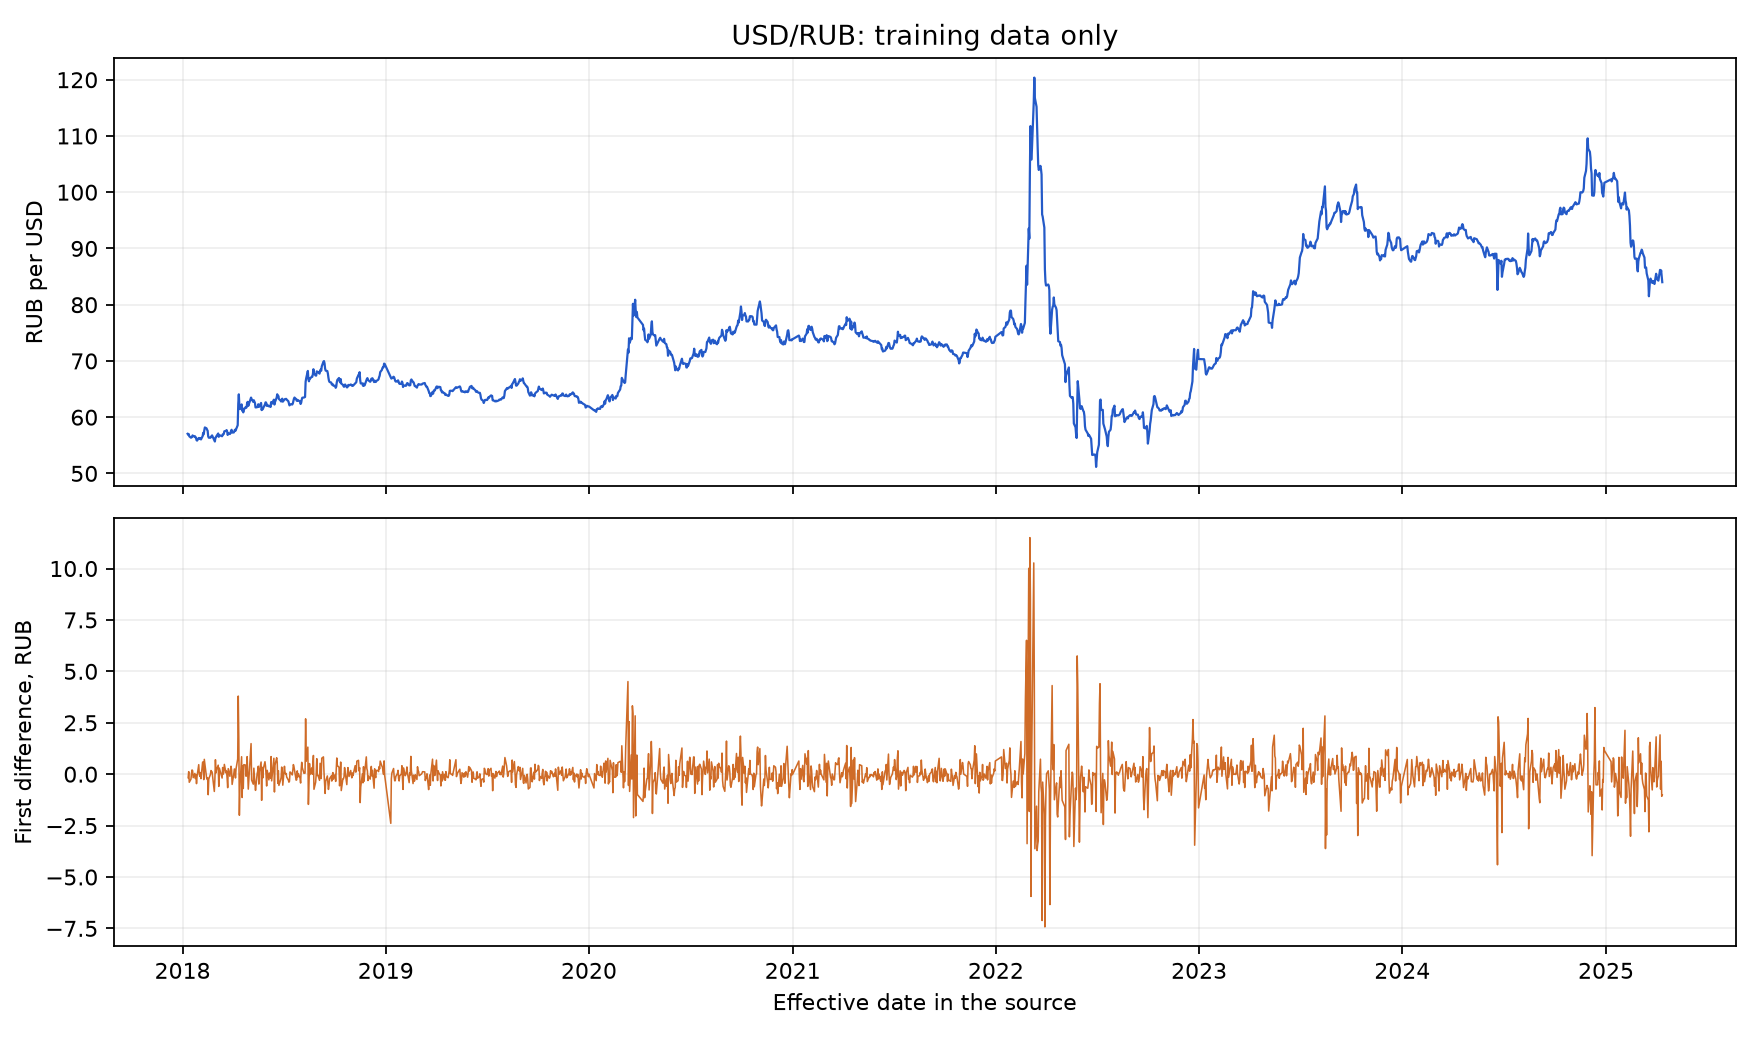

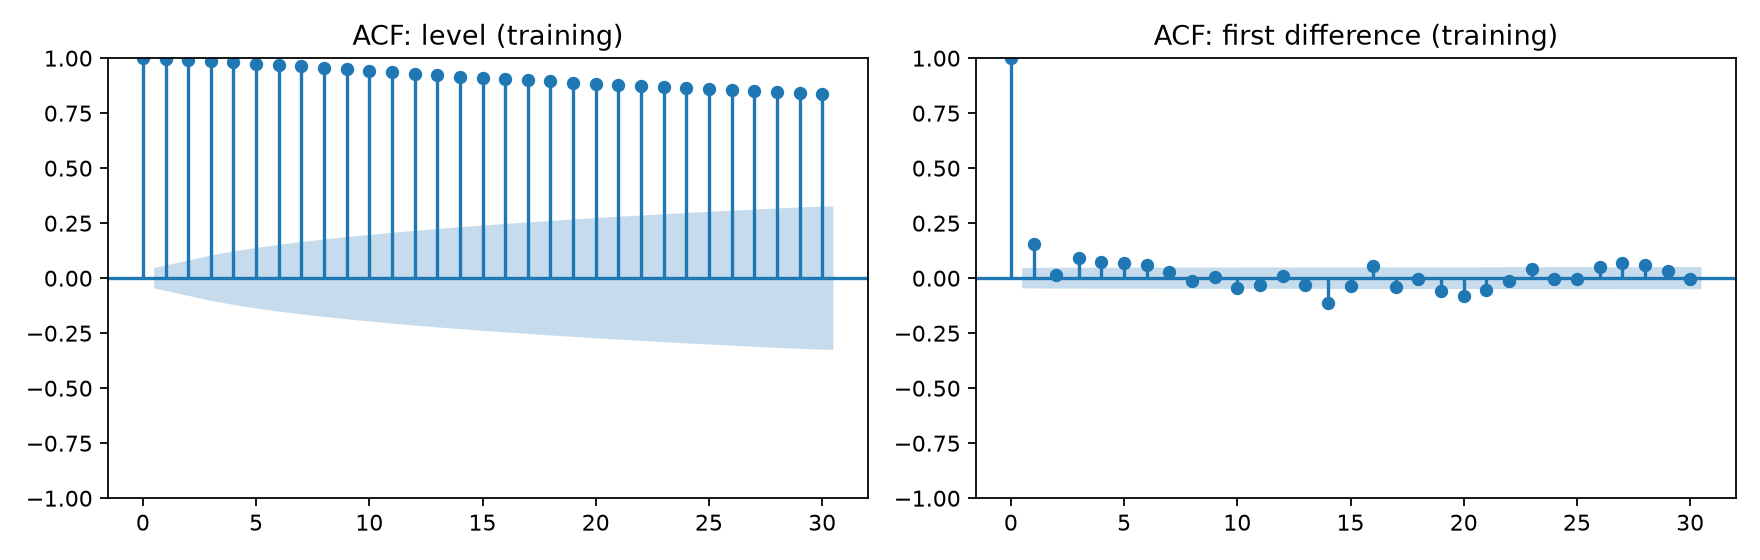

In [4]:
diagnostics = json.loads((ROOT / 'results/diagnostics.json').read_text(encoding='utf-8'))
display(pd.DataFrame({key: value for key, value in diagnostics.items() if key.startswith('adf_')}).T)
print('Резкие изменения сохранены:', diagnostics['jumps_above_3std_kept'])
display(Image(filename=str(ROOT / 'results/history.png')))
display(Image(filename=str(ROOT / 'results/autocorrelation.png')))

## 4. Исследовательская декомпозиция

STL раскладывает среднемесячный ряд Train на тренд, условную сезонную компоненту с периодом 12 и остаток. Сам алгоритм выделяет компоненту при заданном периоде — это не доказательство устойчивой годовой сезонности. Последний неполный месяц исключён.

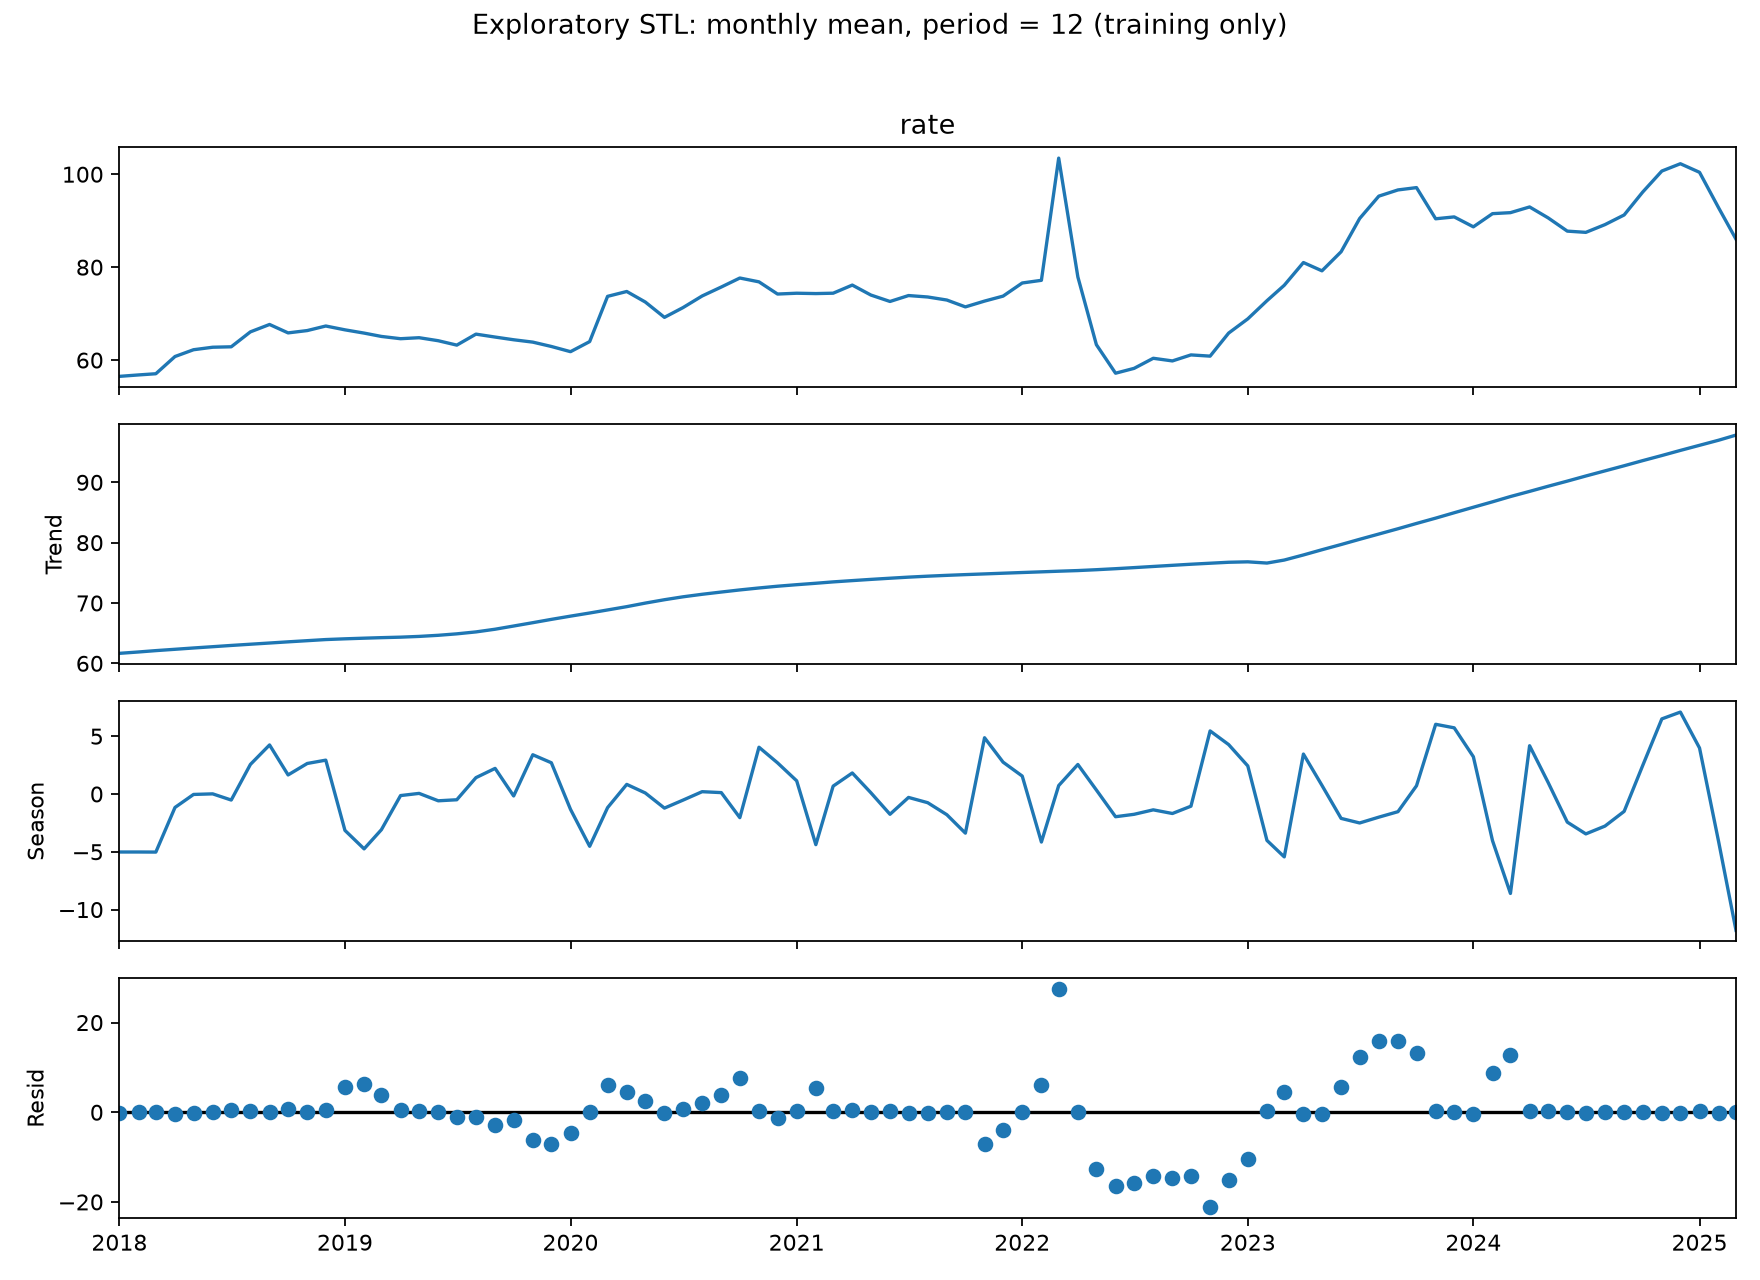

In [5]:
display(Image(filename=str(ROOT / 'results/decomposition.png')))

## 5. Модели и выбор настроек

**Naive:** следующий курс равен последнему известному.

**ARIMA:** небольшая сетка `(p, d, q)`; `d=1` означает внутреннее дифференцирование.

**Prophet:** тренд с двумя настройками гибкости и годовой сезонности. Недельная и дневная сезонность отключены.

Критерий выбора внутри каждой семьи — минимальная WAPE на validation. Одна и та же сетка не перебирается повторно на test.

In [6]:
display(pd.read_csv(ROOT / 'results/validation_metrics.csv'))
selected = json.loads((ROOT / 'results/selected_models.json').read_text(encoding='utf-8'))
print(json.dumps(selected, indent=2, ensure_ascii=False))

,model,config,wape_pct,mae_rub,rmse_rub
0,ARIMA,"(1, 1, 0)",0.355321,0.283929,0.386385
1,Naive,last value,0.358080,0.286133,0.436486
2,ARIMA,"(1, 0, 0)",0.358882,0.286774,0.435767
3,ARIMA,"(0, 1, 1)",0.376078,0.300515,0.406526
4,ARIMA,"(1, 1, 1)",0.387601,0.309723,0.430904
5,Prophet,"{""changepoint_prior_scale"": 0.05, ""yearly_seas...",2.422331,1.935626,2.369707
6,Prophet,"{""changepoint_prior_scale"": 0.01, ""yearly_seas...",10.431679,8.335701,8.866918


{
  "ARIMA": {
    "config": {
      "order": [
        1,
        1,
        0
      ]
    },
    "validation_wape_pct": 0.35532142181228504
  },
  "Prophet": {
    "config": {
      "changepoint_prior_scale": 0.05,
      "yearly_seasonality": true
    },
    "validation_wape_pct": 2.422331235849207
  }
}


## 6. Честная оценка на test

`WAPE = 100 × Σ|факт − прогноз| / Σ|факт|`. MAE — средняя абсолютная ошибка в рублях; RMSE сильнее штрафует крупные ошибки. Улучшение к baseline считается по MAE; положительное значение лучше, отрицательное хуже. На одинаковых датах порядок моделей по WAPE и MAE совпадает.

,model,wape_pct,mae_rub,rmse_rub,improvement_vs_naive_pct
0,Naive,0.6208,0.4991,0.6909,0.0000
1,ARIMA,0.6219,0.5000,0.6919,-0.1815
2,Prophet,1.8923,1.5213,1.8436,-204.8127


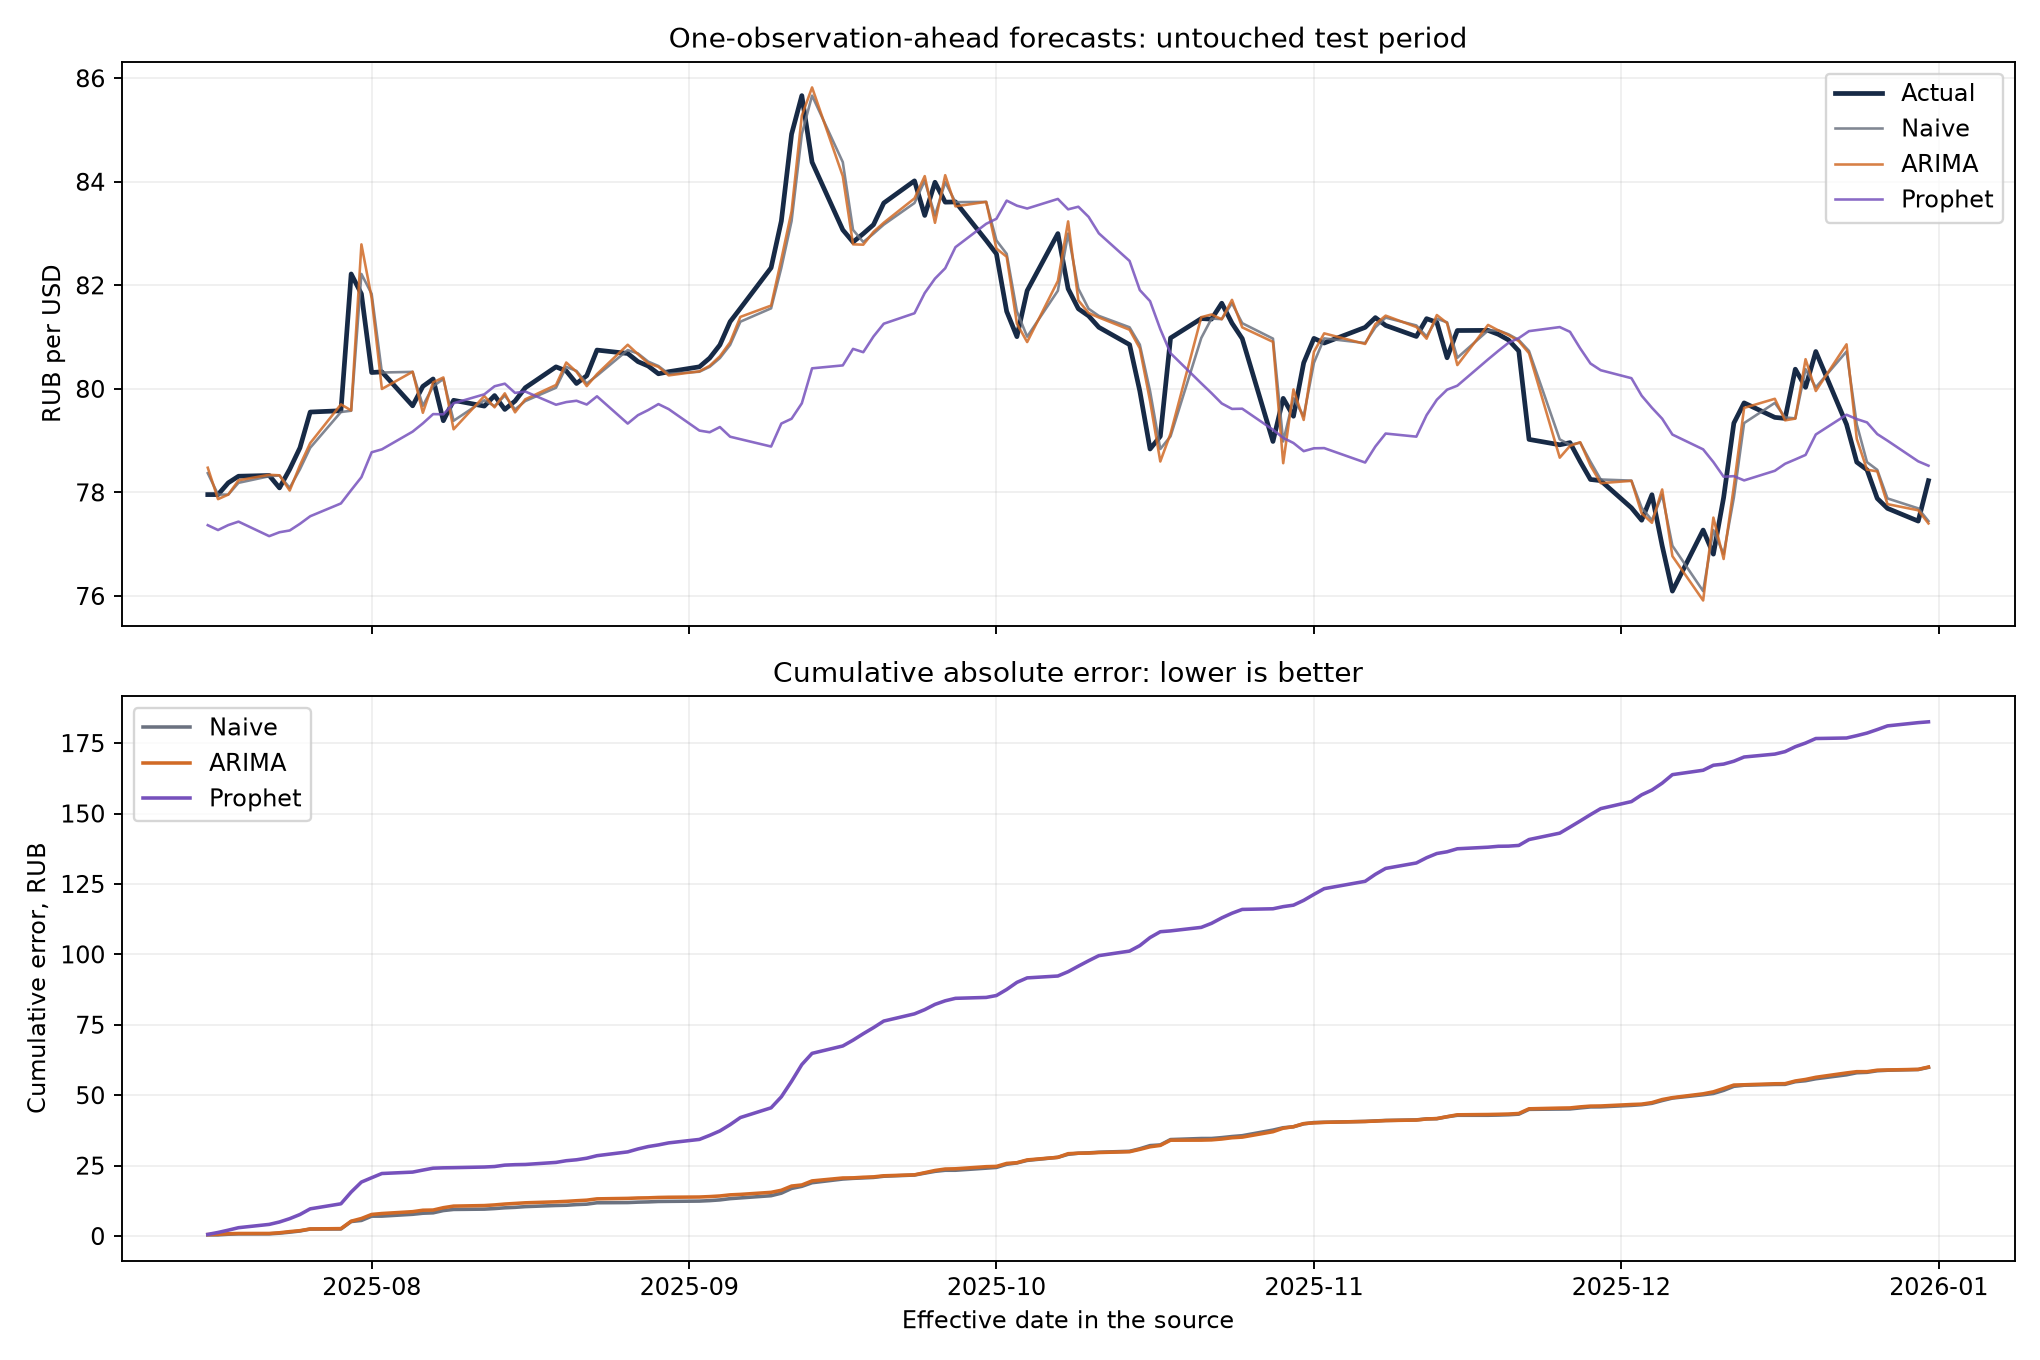

In [7]:
scores = pd.read_csv(ROOT / 'results/test_metrics.csv')
predictions = pd.read_csv(ROOT / 'results/test_predictions.csv', parse_dates=['date', 'history_end'])
assert (predictions.history_end < predictions.date).all()
assert predictions.groupby('model').size().eq(120).all()
assert predictions.groupby('date').actual.nunique().eq(1).all()
for model, group in predictions.groupby('model'):
    calculated = metrics(group.actual, group.prediction)
    saved = scores.loc[scores.model.eq(model)].iloc[0]
    assert abs(calculated['wape_pct'] - saved.wape_pct) < 1e-9
display(scores.round(4))
display(Image(filename=str(ROOT / 'results/backtest.png')))

## 7. Решение и ограничения

Сравнение показывает, оправдано ли усложнение модели на выбранном периоде. Точечный выигрыш по ошибке не подтверждает его статистическую значимость. XML содержит даты действия курса, но не публикации; результат не является проверкой исполнимой торговой стратегии. Внешние факторы не исследуются, поэтому причинные выводы не делаем.

In [8]:
report = (ROOT / 'results/report.md').read_text(encoding='utf-8')
result = report.split('## Результат', 1)[1].split('## Данные', 1)[0]
display(Markdown(result))



На этом test-периоде сложные модели не превзошли последнее известное значение. Для этого горизонта выбираем простой baseline.

| Модель | WAPE, % | MAE, ₽ | RMSE, ₽ | Улучшение MAE к baseline, % |
| --- | ---: | ---: | ---: | ---: |
| Naive | 0.621 | 0.499 | 0.691 | +0.00 |
| ARIMA | 0.622 | 0.500 | 0.692 | -0.18 |
| Prophet | 1.892 | 1.521 | 1.844 | -204.81 |

WAPE = 100 × Σ|факт − прогноз| / Σ|факт|. MAE выражена в рублях за один доллар. Положительное улучшение означает меньшую ошибку, отрицательное — ухудшение. Все модели оценены на одних и тех же 120 наблюдениях. Малая WAPE уровня курса сама по себе не означает, что модель умеет предсказывать изменения курса.



## 8. Что можно объяснить на собеседовании

- Зачем прогноз сравнивать с простым baseline.
- Почему случайное train/test-разделение здесь некорректно.
- Почему скачок курса нельзя автоматически считать ошибкой данных.
- Как отличаются стационарность, сезонность и предсказуемость.
- Почему низкая WAPE уровня курса не доказывает умение прогнозировать его изменения.
- Чем следующий официальный курс отличается от доступного пользователю курса обмена.

Полные выводы и формулировка для анкеты — в [отчёте](results/report.md).